# Analysis: GP-BO vs CMA-ES

Reads the saved runs in `results/<method>/` and compares methods across effective dimension and orientation.
This notebook does not run any optimiser.

**Hypotheses**
- **H1a: Effective dimensionality.** The relative performance of GP-BO and CMA-ES changes as the number of effective dimensions increases.
- **H1b: Rotation.** The relative performance of GP-BO and CMA-ES differs between axis-aligned and rotated objectives.
- **H1c: Interaction.** The effect of rotation on relative performance depends on effective dimension.
- **Methodological consideration: kernel choice.** ARD (flexible) vs isotropic (rotation-invariant) kernels in GP-BO.

## 1. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
RESULTS_DIR = Path("../results")

# Shared experimental settings (match code/cmaes.py and code/shared_bo.py).
D = 20
EFFECTIVE_DIMS = [2, 5, 10, 15, 20]
PROBLEM_SEEDS = [0, 1, 2, 3, 4]
METHOD_SEEDS = [100, 101]
BUDGET = 400

# Methods to compare: results folder name -> plot label.
METHODS = {
    "bo_ard": "GP-BO (ARD)",
    "bo_iso": "GP-BO (isotropic)",
    "cmaes": "CMA-ES",
    "random_search": "Random search",
}

## 2. Load results

Each CSV is one run with one row per evaluation. The filename pattern skips files such as `test_run.csv`.

In [3]:
KEY_COLUMNS = ["method", "d", "problem_seed", "rotated", "method_seed"]


def load_results(results_dir=RESULTS_DIR, methods=METHODS):
    """Combine every saved run into one long table (one row per evaluation)."""
    frames = []
    for method in methods:
        for path in sorted((results_dir / method).glob("d*_problem*_method*.csv")):
            frames.append(pd.read_csv(path))

    if not frames:
        raise FileNotFoundError(f"No result files found in {results_dir}.")

    df = pd.concat(frames, ignore_index=True)
    df["orientation"] = np.where(df["rotated"], "rotated", "aligned")
    return df

In [4]:
df = load_results()

# ARD only for now. To compare methods, use:
# available = [m for m in METHODS if m in set(df["method"])]
available = ["bo_ard"]
df = df[df["method"].isin(available)].reset_index(drop=True)
print("Methods analysed:", [METHODS[m] for m in available])

Methods analysed: ['GP-BO (ARD)']


### 2.1 Checks

Each method should have 5 dims x 5 problems x 2 orientations x 2 method seeds = 100 runs, each with 400 evaluations.

In [5]:
evals_per_run = df.groupby(KEY_COLUMNS).size()
bad_runs = evals_per_run[evals_per_run != BUDGET]
print("Runs without exactly", BUDGET, "evaluations:", len(bad_runs))

expected = len(EFFECTIVE_DIMS) * len(PROBLEM_SEEDS) * 2 * len(METHOD_SEEDS)
runs_per_method = evals_per_run.groupby("method").size()
print(f"\nRuns per method (expected {expected}):")
print(runs_per_method.rename(index=METHODS).to_string())

Runs without exactly 400 evaluations: 0

Runs per method (expected 100):
method
GP-BO (ARD)    100


## 3. Convergence curves

Best value found against evaluations: one panel per effective dimension, aligned vs rotated, one line per method.

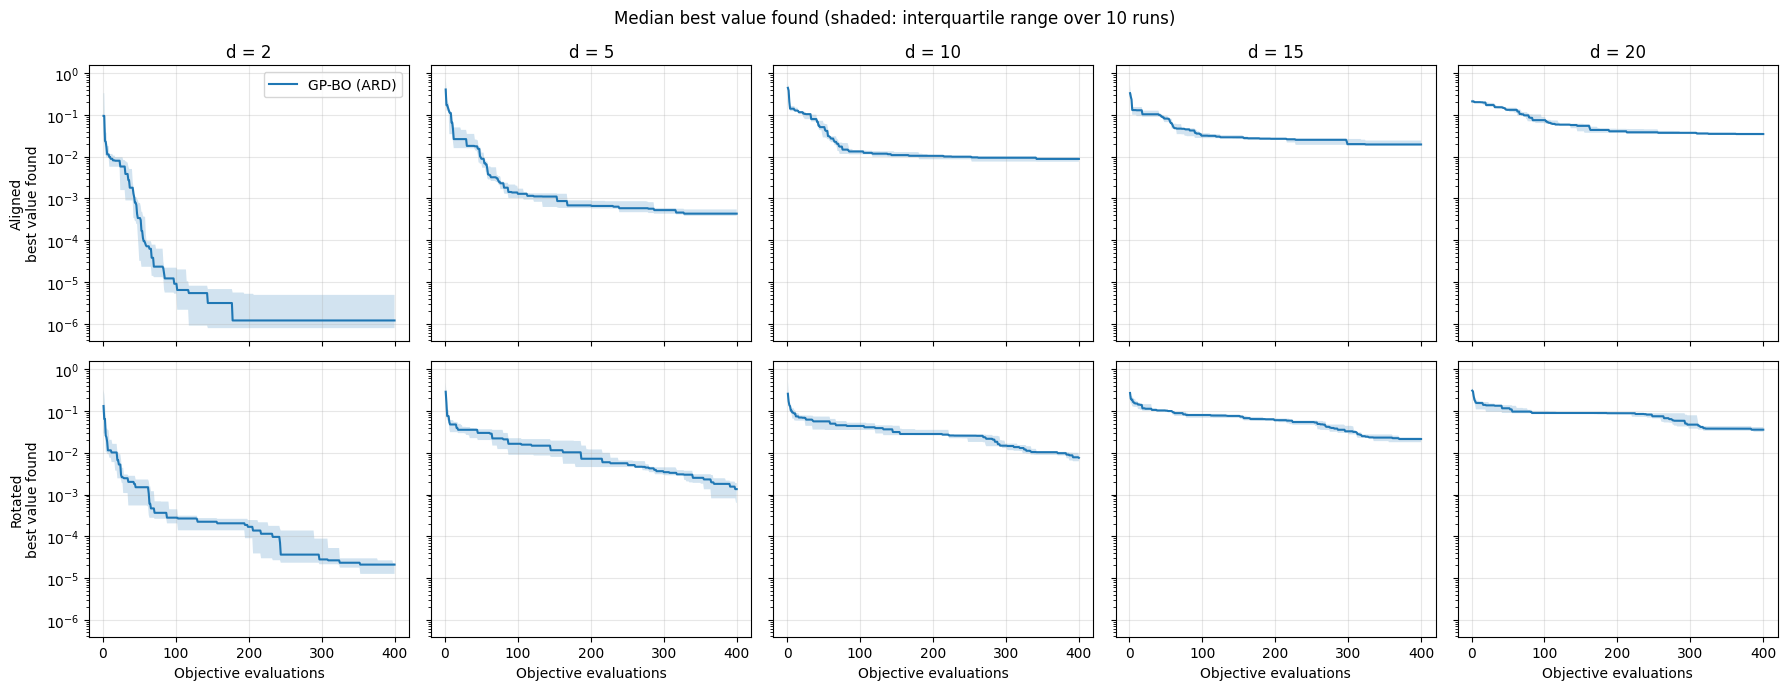

In [6]:
fig, axes = plt.subplots(
    2, len(EFFECTIVE_DIMS), figsize=(18, 7), sharex=True, sharey=True
)

for row, orientation in enumerate(["aligned", "rotated"]):
    for col, d in enumerate(EFFECTIVE_DIMS):
        ax = axes[row, col]
        subset = df[(df["d"] == d) & (df["orientation"] == orientation)]

        for method in available:
            curves = subset[subset["method"] == method].pivot_table(
                index="evaluation",
                columns=["problem_seed", "method_seed"],
                values="best_so_far",
            )
            q25, q50, q75 = (curves.quantile(q, axis=1) for q in (0.25, 0.5, 0.75))
            ax.plot(q50.index, q50, label=METHODS[method])
            ax.fill_between(q50.index, q25, q75, alpha=0.2)

        ax.set_yscale("log")
        ax.grid(True, alpha=0.3)
        if row == 0:
            ax.set_title(f"d = {d}")
        if row == 1:
            ax.set_xlabel("Objective evaluations")
        if col == 0:
            ax.set_ylabel(f"{orientation.capitalize()}\nbest value found")

axes[0, 0].legend()
fig.suptitle("Median best value found (shaded: interquartile range over 10 runs)")
plt.tight_layout()
plt.show()

## 4. Final performance

Summary of `best_so_far` at evaluation 400 (= simple regret, since the minimum is 0).

In [7]:
# One row per run: the best value after the full budget.
final = df[df["evaluation"] == BUDGET].copy()


def q25(x):
    return x.quantile(0.25)


def q75(x):
    return x.quantile(0.75)


summary = (
    final.groupby(["method", "d", "orientation"])["best_so_far"]
    .agg(median="median", q25=q25, q75=q75, mean="mean", runs="size")
    .reset_index()
)
summary["method"] = summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.3g}".format):
    display(summary)

,method,d,orientation,median,q25,q75,mean,runs
0,GP-BO (ARD),2,aligned,1.2e-06,7.86e-07,4.91e-06,4.53e-06,10
1,GP-BO (ARD),2,rotated,2.1e-05,1.26e-05,2.28e-05,2.27e-05,10
2,GP-BO (ARD),5,aligned,0.000433,0.000384,0.000546,0.000445,10
3,GP-BO (ARD),5,rotated,0.00134,0.000632,0.00188,0.00172,10
4,GP-BO (ARD),10,aligned,0.00883,0.00757,0.00964,0.00827,10
5,GP-BO (ARD),10,rotated,0.00755,0.00625,0.00871,0.00908,10
6,GP-BO (ARD),15,aligned,0.0196,0.0184,0.0243,0.0212,10
7,GP-BO (ARD),15,rotated,0.0213,0.0178,0.0233,0.0238,10
8,GP-BO (ARD),20,aligned,0.0348,0.0342,0.0375,0.0358,10
9,GP-BO (ARD),20,rotated,0.0356,0.0317,0.0412,0.0446,10


## 5. H1a: Effective dimensionality

How does each method's final performance change with d, and does the GP-BO vs CMA-ES gap change?

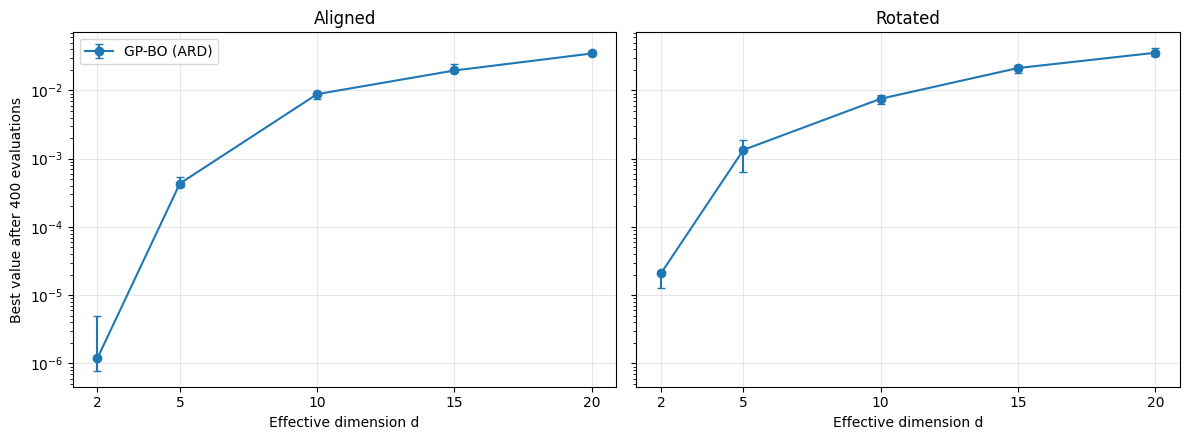

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

for ax, orientation in zip(axes, ["aligned", "rotated"]):
    for method in available:
        values = final[(final["method"] == method) & (final["orientation"] == orientation)]
        stats = values.groupby("d")["best_so_far"].quantile([0.25, 0.5, 0.75]).unstack()
        ax.errorbar(
            stats.index,
            stats[0.5],
            yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
            marker="o",
            capsize=3,
            label=METHODS[method],
        )

    ax.set_yscale("log")
    ax.set_xticks(EFFECTIVE_DIMS)
    ax.set_title(orientation.capitalize())
    ax.set_xlabel("Effective dimension d")
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel(f"Best value after {BUDGET} evaluations")
axes[0].legend()
plt.tight_layout()
plt.show()

## 6. H1b: Rotation

Compare matched aligned/rotated pairs (same d, problem seed and method seed).

In [9]:
# Match each rotated run with its aligned twin (same method, d and seeds).
pairs = final.pivot_table(
    index=["method", "d", "problem_seed", "method_seed"],
    columns="rotated",
    values="best_so_far",
).rename(columns={False: "aligned", True: "rotated"})

# > 0: rotation made the method worse; 1 = ten times worse.
pairs["log10_rotation_effect"] = np.log10(pairs["rotated"] / pairs["aligned"])
pairs = pairs.reset_index()

rotation_summary = (
    pairs.groupby(["method", "d"])["log10_rotation_effect"]
    .agg(median="median", q25=q25, q75=q75)
    .join(
        pairs.groupby(["method", "d"])["log10_rotation_effect"]
        .apply(lambda x: (x > 0).mean())
        .rename("fraction_worse_when_rotated")
    )
    .reset_index()
)
rotation_summary["method"] = rotation_summary["method"].map(METHODS)

with pd.option_context("display.float_format", "{:.2f}".format):
    display(rotation_summary)

,method,d,median,q25,q75,fraction_worse_when_rotated
0,GP-BO (ARD),2,1.25,0.42,1.41,0.90
1,GP-BO (ARD),5,0.39,0.11,0.65,1.00
2,GP-BO (ARD),10,0.04,-0.14,0.11,0.60
3,GP-BO (ARD),15,-0.06,-0.09,0.12,0.40
4,GP-BO (ARD),20,-0.02,-0.04,0.08,0.40


## 7. H1c: Interaction

Does the rotation effect depend on d?

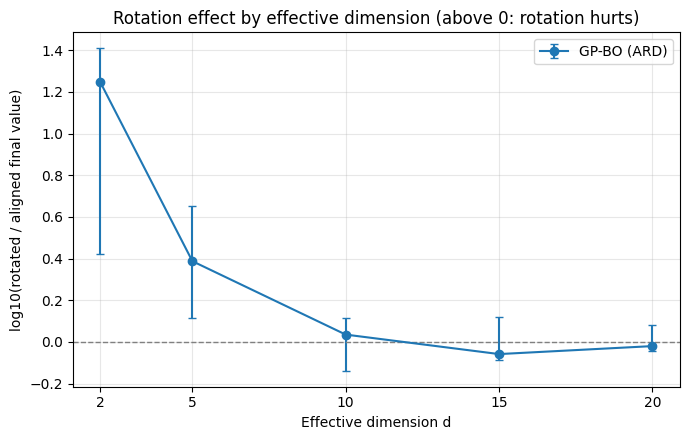

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))

for method in available:
    values = pairs[pairs["method"] == method]
    stats = values.groupby("d")["log10_rotation_effect"].quantile([0.25, 0.5, 0.75]).unstack()
    ax.errorbar(
        stats.index,
        stats[0.5],
        yerr=[stats[0.5] - stats[0.25], stats[0.75] - stats[0.5]],
        marker="o",
        capsize=3,
        label=METHODS[method],
    )

ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(EFFECTIVE_DIMS)
ax.set_xlabel("Effective dimension d")
ax.set_ylabel("log10(rotated / aligned final value)")
ax.set_title("Rotation effect by effective dimension (above 0: rotation hurts)")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 8. Kernel choice: ARD vs isotropic

Compare the two GP-BO variants, and inspect the ARD length scales (short = coordinate treated as important).

In [11]:
if {"bo_ard", "bo_iso"} <= set(available):
    kernels = final[final["method"].isin(["bo_ard", "bo_iso"])].pivot_table(
        index=["d", "orientation", "problem_seed", "method_seed"],
        columns="method",
        values="best_so_far",
    )

    # > 0: ARD found a better (lower) final value than isotropic.
    kernels["log10_iso_over_ard"] = np.log10(kernels["bo_iso"] / kernels["bo_ard"])

    kernel_summary = (
        kernels.groupby(["d", "orientation"])["log10_iso_over_ard"]
        .agg(median="median", q25=q25, q75=q75)
        .unstack("orientation")
    )
    with pd.option_context("display.float_format", "{:.2f}".format):
        display(kernel_summary)
else:
    print("Needs both bo_ard and bo_iso results; available:", available)

Needs both bo_ard and bo_iso results; available: ['bo_ard']


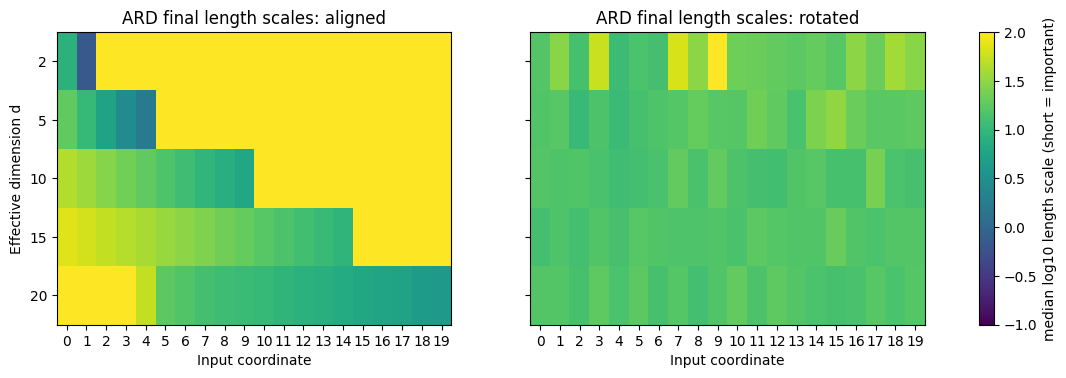

In [12]:
ard_final = final[final["method"] == "bo_ard"]
scale_columns = [f"length_scale{i}" for i in range(D)]

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)

for ax, orientation in zip(axes, ["aligned", "rotated"]):
    # Median log10 length scale per coordinate over the 10 runs per d.
    scales = (
        np.log10(ard_final[ard_final["orientation"] == orientation][scale_columns])
        .groupby(ard_final["d"])
        .median()
        .reindex(EFFECTIVE_DIMS)
    )
    image = ax.imshow(scales, aspect="auto", cmap="viridis", vmin=-1, vmax=2)
    ax.set_title(f"ARD final length scales: {orientation}")
    ax.set_xticks(range(D))
    ax.set_xlabel("Input coordinate")
    ax.set_yticks(range(len(EFFECTIVE_DIMS)))
    ax.set_yticklabels(EFFECTIVE_DIMS)

axes[0].set_ylabel("Effective dimension d")
fig.colorbar(image, ax=axes, label="median log10 length scale (short = important)")
plt.show()

## 9. Runtime

In [13]:
runtime = (
    final.groupby(["method", "d"])["runtime_s"]
    .median()
    .div(60)
    .unstack("d")
    .rename(index=METHODS)
)
print("Median runtime per run (minutes)")
with pd.option_context("display.float_format", "{:.1f}".format):
    display(runtime)

Median runtime per run (minutes)


d,2,5,10,15,20
method,,,,,
GP-BO (ARD),5.6,5.3,5.8,5.5,6.4


## 10. Summary

_Key findings for each hypothesis._